# Bifurcations of continuous piecewise linear systems in two engineering models
### Chua's circuit (two zones, Foco–Centro–Limit-Cycle bifurcation) and the McKean neuron model (three zones, saddle-node of periodic orbits)

This notebook applies the results of Chapters 3, 5 and 6 of the Bachelor's Thesis on continuous piecewise linear (PWL) systems to two engineering/biophysical models. All code cells are **MATLAB** (official *MATLAB Kernel for Jupyter*) and use only core MATLAB (`ode45`, `fzero`, `fminbnd`, `integral`); no toolbox is needed.

**How to run.** Run the cells from top to bottom (*Restart & Run All* takes a few minutes, dominated by the Poincaré-map computations of Section 4). Two technical remarks:

* The MATLAB kernel only keeps *local functions* available inside the cell that defines them. Therefore every cell that needs helper functions (`retmap`, `evline`, ...) defines them at its own end, and the cells that need them are self-contained; ordinary variables and anonymous functions are shared between cells.
* Equation, theorem and proposition numbers refer to the thesis (e.g. "(5.10)", "Theorem 6.2").

---
## 1. Project intention

The theory of Chapters 5 and 6 is formulated for abstract planar continuous PWL systems. The goal of this notebook is to give it **real-world applications**: to show that the two bifurcations studied in the thesis

* the **Foco–Centro–Limit-Cycle (FCLC) bifurcation** of two-zone systems (Chapter 5, Theorem 5.1), and
* the **saddle-node bifurcation of periodic orbits** of three-zone systems (Chapter 6, Theorem 6.2),

actually organise the dynamics of two classical engineering models, and that the *explicit formulas* of the thesis can be used as a recipe: given the physical parameters, they tell us **where** in parameter space the bifurcation takes place and **which initial conditions** produce the periodic orbit, so that a numerical simulation can find it without blind search.

| | System | Zones | Bifurcation | Thesis results used |
|---|---|---|---|---|
| 1 | Chua-type circuit (Chua diode + LC tank) | 2 | FCLC | Prop. 3.3, Thm 5.1, eqs. (5.6), (5.10) |
| 2 | McKean caricature of FitzHugh–Nagumo | 3 | saddle-node of periodic orbits | Prop. 3.5, 3.6, Lemma 6.1, Thm 6.2, eqs. (6.18)–(6.21) |

For each system the workflow is the one of the thesis: **(a)** bring the system to its canonical form, **(b)** use the formulas of the theorems to obtain the initial values of the periodic orbit as functions of the parameters, **(c)** simulate and plot, **(d)** interpret the results.

---
## 2. Definition of the two systems

### 2.1 System 1 — Chua's circuit (two zones)

**What it models.** Chua's circuit is the paradigm of nonlinear electronics: two capacitors $C_1,C_2$, an inductor $L$, a linear resistor $R$ and a *Chua diode*, an active nonlinear resistor with a continuous piecewise linear $i$–$v$ characteristic (Example 3.1 of the thesis, system (3.1)). Its PWL nonlinearity is exactly what makes the model tractable, and it produces everything from equilibria and oscillations to chaos (the double-scroll attractor).

**Why a planar two-zone version.** The theory of Chapter 5 is *planar* and for *two zones*, whereas the full circuit (3.1) is three-dimensional. The oscillatory core of the circuit is the LC tank loaded by the Chua diode; it is recovered exactly when the coupling resistor vanishes, $R\to0$, because then $v_{C_1}=v_{C_2}=v$ and the two capacitors merge into $C=C_1+C_2$. With a small series loss $R_0$ in the inductor and a Chua diode with one breakpoint we obtain the second-order circuit

$$C\,\dot v=-i-i_N(v),\qquad L\,\dot i=v-R_0\,i .$$

With $u=v/V_b$, $j=iZ_0/V_b$, $s=t/\sqrt{LC}$, $Z_0=\sqrt{L/C}$, $r=R_0/Z_0$ and a diode characteristic with slope $g_L$ inside, slope $g_R$ outside and breakpoint $(u_b,c_b)$ the system becomes, in the coordinates $x=(u-u_b,\;j)$ (breakpoint on $\{x_1=0\}$),

$$x'=\begin{cases}A_L x+b,& x_1\le 0\\ A_R x+b,& x_1>0\end{cases},\qquad A_{L,R}=\begin{pmatrix}-g_{L,R}&-1\\1&-r\end{pmatrix},\quad b=\begin{pmatrix}-c_b\\u_b\end{pmatrix},$$

a continuous two-zone planar PWL system of the form (3.7) (the second columns of $A_L,A_R$ and the vector $b$ coincide).

![Chua's circuit](figures/fig1_chua_circuit.png)

**What we want to obtain: the FCLC bifurcation.** Let $T_L=\operatorname{tr}A_L=-g_L-r$ be the net damping in the inner zone. When $T_L$ crosses $0$ (the negative conductance of the diode exactly compensates the losses) the system goes through the sequence of Section 3.5:

1. $T_L<0$: the equilibrium is a **stable focus** (oscillations decay);
2. $T_L=0$: the equilibrium is a **centre** of the inner linear system, surrounded by a family of periodic orbits; the largest one is an ellipse tangent to the separation line;
3. $T_L>0$ small: the equilibrium is an unstable focus and **a stable limit cycle** crossing the separation line appears near the tangent ellipse (Theorem 5.1).

**Physical interpretation.** This is how an electronic oscillator starts: when the active element supplies slightly more power than the circuit dissipates ($T_L>0$) any perturbation grows, until the outer segment of the diode (which dissipates, $T_R<0$) limits the amplitude. The limit cycle is a **sustained oscillation** of the voltage and current. Note that the amplitude does not start from zero: the oscillation appears with a finite amplitude (set by the tangent ellipse) as soon as $T_L>0$.

### 2.2 System 2 — McKean model (three zones)

**What it models.** McKean's piecewise linear caricature of the FitzHugh–Nagumo model (Example 3.2, system (3.2)) describes the dynamics of the action potential of a neuron: $v$ is the membrane potential, $w$ a slow recovery variable and $I$ the applied current,

$$\varepsilon v'=f(v)-w+I,\qquad w'=v-\gamma w .$$

The function $f$ is continuous and piecewise linear with three zones, $\{v\le0\}$ (rest), $\{0<v\le1\}$ (activation) and $\{v>1\}$ (repolarisation). We write its slopes as $(s_L,s_C,s_R)$; in the thesis $(s_L,s_C,s_R)=(-1,a-1,-1)$.

![McKean model](figures/fig3_mckean_neuron_schematic.png)


**What we want to obtain: the saddle-node bifurcation of periodic orbits.** After the normalisation of Propositions 3.5–3.6 the system depends on $(t_L,d_L,t_R,d_R)$ (outer zones) and on two free parameters $(m,a_C)$: $m=-T_C/\sqrt{D_C}$ is the (normalised) trace of the central zone and $a_C$ the position of its equilibrium. For $(m,a_C)=(0,0)$ the central zone is a centre foliated by circles, and the unit circle $\Gamma_0$ is tangent to both separation lines. Near $(0,0)$ there is a curve $a_C=a_C^*(m)$ such that (Theorem 6.2), depending on the sign of $\sigma\,(a_C-a_C^*(m))$ with $\sigma=t_Lt_R(t_L^2-t_R^2)$:

* **two** limit cycles (one stable, one unstable) near $\Gamma_0$,
* **one semi-stable** limit cycle on the curve,
* **none** on the other side.

**Physical interpretation.** For $m>0$ the equilibrium is a stable focus (the neuron is at *rest*). If the stimulus is on the "none" side the neuron can only be at rest. Crossing the curve, a *pair* of cycles is born: the stable one is **repetitive firing** and the unstable one is the **threshold** that separates rest from firing. The neuron becomes bistable (rest *or* spiking, depending on the size of the perturbation): this is the transition between rest and neuronal firing with a finite-amplitude, hysteretic onset.

> **Important remark on the hypotheses.** Theorem 6.2 requires $t_L\,t_R<0$ (the outer zones must have opposite sign of the trace). For the **standard** McKean model of Example 3.2 the two outer matrices are identical, $A_1=A_3$, so $t_L=t_R$ and the hypothesis fails. The notebook checks this explicitly (Section 4a, and the first panel of Figure 5 in Section 4c) and then applies Chapter 6 to the minimal modification that satisfies the hypothesis, an **asymmetric McKean caricature** in which only the slope of the outer-right branch is changed ($s_R=-1\to s_R=+1$).

In [1]:
%% Global set-up (run this cell first)
clear; close all; clc;
format short g
% Plot defaults. Colours are fixed explicitly so that figures are drawn on a white background
% (independently of a dark MATLAB / Jupyter theme).
set(groot, 'DefaultAxesFontSize', 11, 'DefaultLineLineWidth', 1.4, 'DefaultAxesBox', 'on', ...
    'DefaultFigureColor', 'w', 'DefaultAxesColor', 'w', 'DefaultAxesXColor', 'k', ...
    'DefaultAxesYColor', 'k', 'DefaultAxesZColor', 'k', 'DefaultAxesGridColor', [.15 .15 .15], ...
    'DefaultTextColor', 'k', 'DefaultLegendColor', 'w', 'DefaultLegendTextColor', 'k', ...
    'DefaultLegendEdgeColor', [.15 .15 .15]);
disp(['MATLAB release: ' version('-release') '  (only core MATLAB is used: ode45, fzero, fminbnd, integral)'])


MATLAB release: 2026b  (only core MATLAB is used: ode45, fzero, fminbnd, integral)


---
## 3. System 1 — Chua-type oscillator: FCLC bifurcation (Chapters 3 and 5)

### 3a. Transformation to the Liénard canonical form (Proposition 3.3)

For a two-zone system (3.7) with $a_{12}\neq0$, the change of variables
$$x=x_1,\qquad y=a_{22}x_1-a_{12}x_2-b_1$$
transforms it into the canonical form (3.8)
$$\begin{pmatrix}x'\\y'\end{pmatrix}=\begin{cases}\begin{pmatrix}T_L&-1\\D_L&0\end{pmatrix}\begin{pmatrix}x\\y\end{pmatrix}-\begin{pmatrix}0\\a\end{pmatrix},&x\le0\\[2mm]\begin{pmatrix}T_R&-1\\D_R&0\end{pmatrix}\begin{pmatrix}x\\y\end{pmatrix}-\begin{pmatrix}0\\a\end{pmatrix},&x>0\end{cases}\qquad T_k=\operatorname{tr}A_k,\; D_k=\det A_k,\; a=a_{12}b_2-a_{22}b_1 .$$

For our circuit $a_{12}=-1$, $a_{22}=-r$, so $T_L=-g_L-r$, $D_L=1+g_Lr$, $T_R=-g_R-r$, $D_R=1+g_Rr$ and $a=-u_b-rc_b$. The cell below builds the matrices, computes the canonical data, **verifies numerically** that the change of variables conjugates the two vector fields, and checks the hypotheses of Theorem 5.1: $a<0$, $T_R<0$, $4D_L-T_L^2>0$. It also translates the dimensionless parameters into component values (illustrative values in the range of the classical circuit: $L=18$ mH, $C_1+C_2=110$ nF, $V_b=1$ V).

In [2]:
%% 3a.  Chua-type oscillator -> Lienard canonical form (Proposition 3.3)
% ---- dimensionless parameters of the planar two-zone circuit ------------
r   = 0.10;   % series loss of the inductor, r = R0/Z0   (Z0 = sqrt(L/C))
gR  = 0.50;   % slope of the OUTER segment of the Chua diode   (G_out*Z0 > 0)
ub  = 1.00;   % breakpoint voltage of the diode            (units of Vb)
cb  = 0.20;   % diode current at the breakpoint            (units of Vb/Z0)

% ---- the two linear zones of  x' = A x + b,  with x = (x1,x2) = (u-ub, j) ----
% The inner slope gL is the parameter that will be varied (bias of the Chua diode).
AL = @(gL) [-gL  -1;   1  -r];        % zone {x1 <= 0}: inner segment, slope gL
AR = [-gR  -1;   1  -r];              % zone {x1 >  0}: outer segment, slope gR
b  = [-cb; ub];                       % the SAME vector in both zones (continuity, eq. (3.7))

gL0 = -r - 1e-3;                      % a value slightly beyond the critical one (TL = 1e-3)
fprintf('--- Original (piecewise-linear) form, gL = %.4f ---\n', gL0);
disp('A_L ='); disp(AL(gL0));  disp('A_R ='); disp(AR);  disp('b ='); disp(b);

% ---- Proposition 3.3:  x = x1,  y = a22*x1 - a12*x2 - b1 ---------------------
a12 = AR(1,2);  a22 = AR(2,2);  b1 = b(1);  b2 = b(2);
Q = [1 0;  a22 -a12];   q = [0; -b1];            % (x;y) = Q*(x1;x2) + q
a  = a12*b2 - a22*b1;                            % constant "a" of the canonical form
TLf = @(gL) trace(AL(gL));   DLf = @(gL) det(AL(gL));
TL0 = TLf(gL0);  DL0 = DLf(gL0);  TR = trace(AR);  DR = det(AR);

CL = [TL0 -1; DL0 0];   CR = [TR -1; DR 0];      % canonical matrices of eq. (3.8)
fprintf('\n--- Lienard canonical form (3.8): x'' = C*(x,y)^T - (0,a)^T ---\n');
disp('C_L = [TL -1; DL 0] ='); disp(CL);
disp('C_R = [TR -1; DR 0] ='); disp(CR);
fprintf('a  = a12*b2 - a22*b1 = %.4f\n', a);
fprintf('TL = %.4g,  DL = %.4f,  TR = %.4f,  DR = %.4f\n', TL0, DL0, TR, DR);

% ---- numerical check that the change of variables really conjugates the flows ----
rng(1);  err = 0;
for k = 1:500
    x12 = 3*randn(2,1);  z = Q*x12 + q;                       % point in both coordinate systems
    if x12(1) <= 0, lhs = Q*(AL(gL0)*x12 + b);  rhs = CL*z - [0;a];
    else,           lhs = Q*(AR*x12 + b);       rhs = CR*z - [0;a];  end
    err = max(err, norm(lhs - rhs));
end
fprintf('\nMax. mismatch of the vector fields after the change of variables: %.2e\n', err);

% ---- hypotheses of Theorem 5.1 ------------------------------------------
fprintf('\nHypotheses of Theorem 5.1:  a<0: %d | TR<0: %d | DL>0: %d | |TL|<2*sqrt(DL): %d\n', ...
        a<0, TR<0, DL0>0, abs(TL0) < 2*sqrt(DL0));
xeq = a/DL0;  yeq = TL0*a/DL0;
fprintf('Unique equilibrium in {x<0} (canonical coordinates): (%.4f, %.3e)\n', xeq, yeq);

% ---- physical meaning of the dimensionless parameters (illustrative values) ----
Lind = 18e-3;  Ceq = 110e-9;  Vb = 1;                  % C1 + C2 of the classical circuit, R -> 0
Z0 = sqrt(Lind/Ceq);  tau0 = sqrt(Lind*Ceq);
fprintf('\nPhysical scales: Z0 = %.1f Ohm, time unit sqrt(LC) = %.2f us, natural frequency %.2f kHz\n', ...
        Z0, tau0*1e6, 1e-3/(2*pi*tau0));
fprintf('R0 = %.1f Ohm | G_out = %.3f mS | critical inner slope G_in = %.3f mS | breakpoint (%.1f V, %.3f mA)\n', ...
        r*Z0, 1e3*gR/Z0, 1e3*(-r)/Z0, ub*Vb, 1e3*cb*Vb/Z0);


--- Original (piecewise-linear) form, gL = 

-0.1010

 ---


A_L =


        0.101           -1
            1         -0.1



...

 mS | breakpoint (

1.0

 V, 

0.494

 mA)


### 3b. Initial values from the theory (Theorem 5.1)

With $a<0$, $D_L>0$, $T_R<0$ and $T_L\in(0,\delta)$ small, Theorem 5.1 states that (5.1) has a **stable limit cycle** crossing $\{x=0\}$ at $(0,y_0)$ and $(0,y_1)$, where, inverting the series $T_L^*(y_0)$ with Lagrange's theorem, (5.10):
$$y_0^*(T_L)=\Big(\tfrac{3\pi}{2}\Big)^{1/3}\big(a^{-3}D_L^{3/2}T_R\big)^{-1/3}T_L^{1/3}-2^{-2/3}3^{-1/3}a^{-1}\pi^{2/3}T_R\big(a^{-3}D_L^{3/2}T_R\big)^{-2/3}T_L^{2/3}+\mathcal O(T_L),$$
and, with Theorem 5.1 / (5.6) / (5.8),
$$y_1=-y_0-\frac{2T_R}{3a}y_0^2-\frac{4T_R^2}{9a^2}y_0^3+\frac{2(9D_RT_R-22T_R^3)}{135a^3}y_0^4+\frac{4(27D_RT_R^2-26T_R^4)}{405a^4}y_0^5+\mathcal O(y_0^6),$$
$$T=\frac{4\pi}{\sqrt{4D_L-T_L^2}}+\int_{y_1}^{y_0}\frac{a\,dy}{a^2-aT_Ly+D_Ly^2}+\int_{y_1}^{y_0}\frac{-a\,dy}{a^2-aT_Ry+D_Ry^2}\quad\text{(period).}$$
The cell evaluates these formulas as functions of $T_L$. In our circuit $T_L$ is tuned with the inner slope of the Chua diode, $T_L=-g_L-r$ (hence $D_L=1+g_Lr$ is evaluated at the actual $g_L$).

In [3]:
%% 3b.  Initial values predicted by Theorem 5.1:  y0*(TL) from (5.10),  y1 from (5.6)/(5.8)
% TL is tuned through the inner slope of the Chua diode:  TL = -gL - r  (so DL = 1 + gL*r also moves slightly).
gL_of_TL = @(TL) -r - TL;
DL_of_TL = @(TL) DLf(gL_of_TL(TL));

% Equation (5.10):  y0 = (3*pi/2)^(1/3) * K^(-1/3) * TL^(1/3)
%                      - 2^(-2/3) 3^(-1/3) pi^(2/3) (TR/a) * K^(-2/3) * TL^(2/3) + O(TL),   K = a^-3 DL^(3/2) TR > 0
Kc   = @(DL) a^-3 * DL^(3/2) * TR;
c1   = @(DL)  (3*pi/2)^(1/3) * Kc(DL)^(-1/3);
c2   = @(DL) -2^(-2/3) * 3^(-1/3) * pi^(2/3) * (TR/a) * Kc(DL)^(-2/3);
y0_1term = @(TL)  c1(DL_of_TL(TL)) .* TL.^(1/3);
y0_2term = @(TL)  y0_1term(TL) + c2(DL_of_TL(TL)) .* TL.^(2/3);

% Theorem 5.1: the lower crossing point (0,y1) and the period of the limit cycle
y1_series = @(y0) -y0 - 2*TR/(3*a)*y0.^2 - 4*TR^2/(9*a^2)*y0.^3 ...
                  + 2*(9*DR*TR - 22*TR^3)/(135*a^3)*y0.^4 + 4*(27*DR*TR^2 - 26*TR^4)/(405*a^4)*y0.^5;
period_thm = @(y0,y1,TL,DL) 4*pi/sqrt(4*DL - TL^2) ...
           + integral(@(y)  a./(a^2 - a*TL*y + DL*y.^2), y1, y0) ...
           + integral(@(y) -a./(a^2 - a*TR*y + DR*y.^2), y1, y0);

TLgrid = [1e-5 1e-4 1e-3 5e-3 1e-2 2e-2];
fprintf('  TL        gL(mS)   y0*(1 term)  y0*(2 terms)   y1(series)   T (Thm 5.1, units of sqrt(LC))\n');
for k = 1:numel(TLgrid)
    TLk = TLgrid(k);  DLk = DL_of_TL(TLk);
    y0k = y0_2term(TLk);  y1k = y1_series(y0k);
    fprintf('%8.1e  %8.4f   %10.5f   %11.5f   %10.5f   %10.5f\n', TLk, 1e3*gL_of_TL(TLk)/Z0, ...
            y0_1term(TLk), y0k, y1k, period_thm(y0k, y1k, TLk, DLk));
end
fprintf('\nNote: y0* grows like TL^(1/3) (infinite slope at TL = 0): a tiny excess of negative damping already gives a macroscopic oscillation.\n');


  TL        gL(mS)   y0*(1 term)  y0*(2 terms)   y1(series)   T (Thm 5.1, units of sqrt(LC))


 1.0e-05

 -0.2472

   0.04390

    0.04352

...

   0.55368

    0.49357

  -0.60501

   6.31845


Note: y0* grows like TL^(1/3) (infinite slope at TL = 0): a tiny excess of negative damping already gives a macroscopic oscillation.


### 3c. Simulation of the bifurcation

The initial value $(0,y_0^*)$ given by (5.10) is only an *asymptotic* (small $T_L$) approximation. We therefore proceed in three steps:

1. take $(0,y_0^*)$ from (5.10) as initial condition;
2. measure how far it is from the true periodic orbit by solving $P(y)=y$, where $P$ is the exact Poincaré return map of $\{x=0\}$ (computed with `ode45` and event detection); the fixed point is the cycle, and its Floquet multiplier is $\mu=e^{T_L\tau_L+T_R\tau_R}$ (Section 5.3), which we also check against a finite-difference derivative of $P$;
3. integrate orbits that start on, inside and outside the cycle to show that it attracts them.

**Figures.** Figure 1 reproduces the three panels of Figure 3.3 (stable focus / centre with tangent ellipse / stable limit cycle). Figure 2 zooms at the separation line and shows the return map with a cobweb diagram started at the theoretical value. Figure 3 shows the voltage across the capacitor in the real circuit for the three regimes.

TL = 

0.001

  y0 : theory (5.10) = 

0.19564

 | numerical = 

...

  after 25 returns: 

0.198724

  (limit cycle: 

0.198733

)


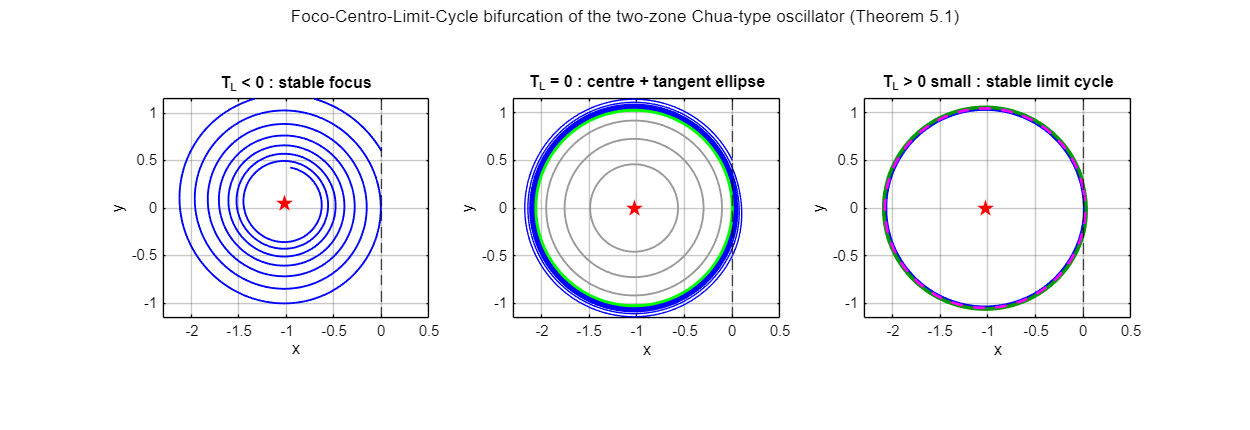

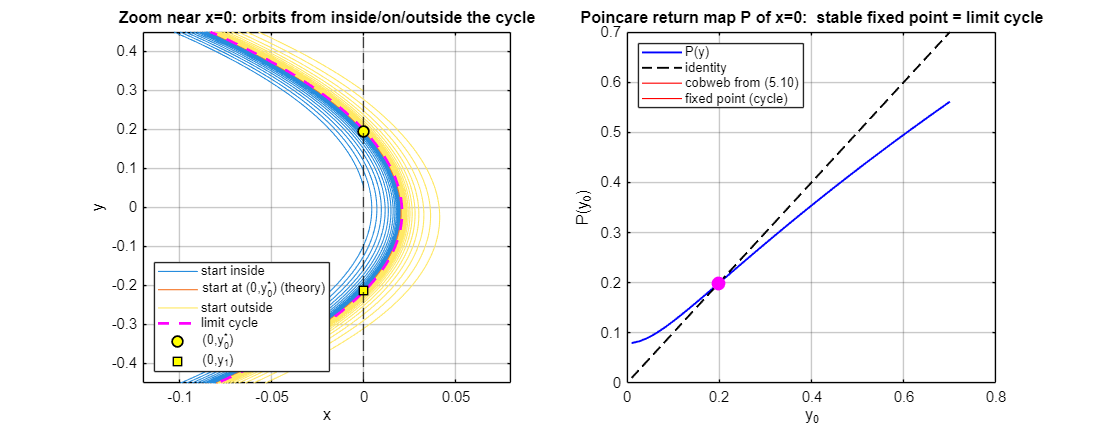

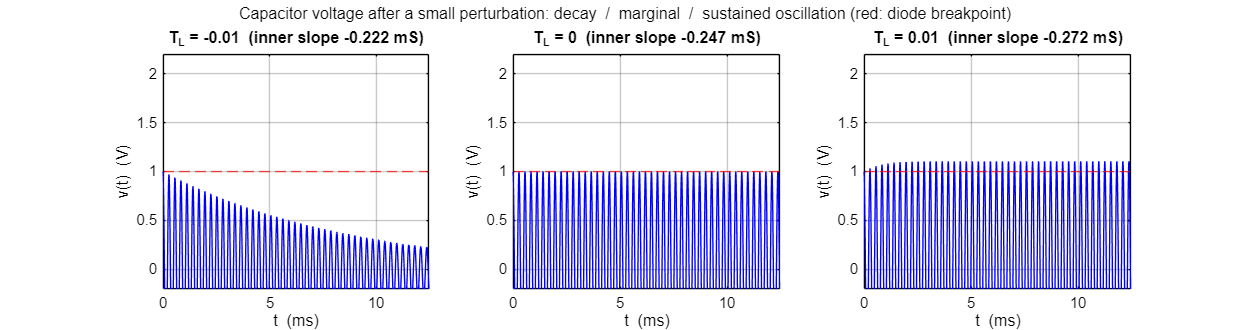

In [4]:
%% 3c-i.  Simulation of the FCLC bifurcation: limit cycle and the three regimes TL<0, TL=0, TL>0
TLdemo = 1e-3;                                          % supercritical value used for the limit cycle
mkp = @(TL) struct('TL',TL, 'DL',DL_of_TL(TL), 'TR',TR, 'DR',DR, 'a',a);   % parameter set of system (5.1)
p   = mkp(TLdemo);

% (1) initial value predicted by the theory, eq. (5.10) with two terms
y0_th = y0_2term(TLdemo);
% (2) how good is it?  Solve P(y)=y with the exact (numerical) Poincare return map of {x=0}
y0_num = fzero(@(y) retmap(y,p) - y, [0.5 1.6]*y0_th);
[~, y1_num, tauL, tauR] = retmap(y0_num, p);
mu = exp(p.TL*tauL + p.TR*tauR);                        % Floquet multiplier, Section 5.3
h  = 1e-6;  mu_fd = (retmap(y0_num+h,p) - retmap(y0_num-h,p))/(2*h);   % finite-difference check
fprintf('TL = %g\n', TLdemo);
fprintf('  y0 : theory (5.10) = %.5f | numerical = %.5f | relative error = %.2f %%\n', y0_th, y0_num, 100*abs(y0_th-y0_num)/y0_num);
fprintf('  y1 : Theorem 5.1   = %.5f | numerical = %.5f\n', y1_series(y0_num), y1_num);
fprintf('  period T = %.5f (simulation)  vs  %.5f (Theorem 5.1 integral formula)\n', tauL+tauR, period_thm(y0_num,y1_num,p.TL,p.DL));
fprintf('  Floquet multiplier mu = %.5f (exp(TL*tauL+TR*tauR))  vs  %.5f (finite differences)  ->  stable: %d\n', mu, mu_fd, mu<1);

% (3) start exactly at (0, y0_th) and iterate the return map: the orbit is attracted by the limit cycle
yk = y0_th;  yh = yk;
for k = 1:25, yk = retmap(yk,p);  yh(end+1) = yk;  end %#ok<SAGROW>
fprintf('  successive returns starting at the theoretical value: %s ...\n', sprintf('%.5f ', yh(1:5)));
fprintf('  after 25 returns: %.6f  (limit cycle: %.6f)\n', yh(end), y0_num);

%% Figure 1 -- phase portraits in canonical coordinates (cf. Figure 3.3 of the thesis)
opts = odeset('RelTol',1e-10,'AbsTol',1e-12);
TLs  = [-0.05, 0, TLdemo];   tends = [45, 120, 260];
titles = {'T_L < 0 : stable focus', 'T_L = 0 : centre + tangent ellipse', 'T_L > 0 small : stable limit cycle'};
figure('Position',[50 50 1250 430]);
for k = 1:3
    pk = mkp(TLs(k));  f = @(t,X) lienard(t,X,pk);
    subplot(1,3,k); hold on; grid on;
    xe = pk.a/pk.DL;  ye = pk.TL*pk.a/pk.DL;                      % equilibrium of the left zone
    switch k
        case 1                                                    % spiral towards the focus
            [~,X] = ode45(f,[0 tends(k)],[0; 0.6],opts);   plot(X(:,1),X(:,2),'b');
        case 2                                                    % family of closed ellipses + attracted orbit
            th = linspace(0,2*pi,400);
            for lev = -[0.2 0.5 0.8]*a^2/pk.DL                    % closed orbits  y^2 + DL x^2 - 2 a x = lev < 0
                rx = sqrt((lev + a^2/pk.DL)/pk.DL);  ry = sqrt(lev + a^2/pk.DL);
                plot(xe + rx*cos(th), ry*sin(th), 'Color', [.6 .6 .6]);
            end
            rx = abs(a)/pk.DL;  ry = abs(a)/sqrt(pk.DL);          % ellipse tangent to {x=0}  (lev = 0)
            [~,X] = ode45(f,[0 tends(k)],[0; 0.5],opts);   plot(X(:,1),X(:,2),'b','LineWidth',0.6);
            plot(xe+rx*cos(th), ry*sin(th), 'g', 'LineWidth', 2.2);
        case 3                                                    % limit cycle + orbits from both sides
            [~,Xs] = ode45(f,[0 tends(k)],[0; y0_th],opts);        plot(Xs(:,1),Xs(:,2),'k','LineWidth',0.6);
            [~,Xi] = ode45(f,[0 tends(k)],[0; 0.05],opts);         plot(Xi(:,1),Xi(:,2),'b','LineWidth',0.6);
            [~,Xo] = ode45(f,[0 tends(k)],[0; 1.5*y0_num],opts);   plot(Xo(:,1),Xo(:,2),'Color',[0 .6 0],'LineWidth',0.6);
            [~,Xc] = ode45(f,[0 tauL+tauR],[0; y0_num],opts);      plot(Xc(:,1),Xc(:,2),'m--','LineWidth',2);
    end
    plot(xe, ye, 'rp', 'MarkerFaceColor','r', 'MarkerSize', 9);     % equilibrium
    xline(0,'k--');  axis equal;  xlim([-2.3 0.5]);  ylim([-1.15 1.15]);
    xlabel('x'); ylabel('y'); title(titles{k});
end
sgtitle('Foco-Centro-Limit-Cycle bifurcation of the two-zone Chua-type oscillator (Theorem 5.1)', 'Color', 'k');

%% Figure 2 -- zoom on the separation line and Poincare return map for TL = 1e-3
figure('Position',[50 50 1100 430]);
subplot(1,2,1);  hold on;  grid on;
f = @(t,X) lienard(t,X,p);
for y00 = [0.05, y0_th, 1.5*y0_num]
    [~,X] = ode45(f,[0 150],[0; y00],opts);  plot(X(:,1), X(:,2), 'LineWidth', 0.8);
end
[~,Xc] = ode45(f,[0 tauL+tauR],[0; y0_num],opts);  plot(Xc(:,1),Xc(:,2),'m--','LineWidth',2);
plot(0,y0_th,'ko','MarkerFaceColor','y','MarkerSize',8);  plot(0,y1_series(y0_th),'ks','MarkerFaceColor','y','MarkerSize',8);
xline(0,'k--');  xlim([-0.12 0.08]);  ylim([-0.45 0.45]);  xlabel('x');  ylabel('y');
title('Zoom near {x=0}: orbits from inside/on/outside the cycle');
legend('start inside','start at (0,y_0^*) (theory)','start outside','limit cycle','(0,y_0^*)','(0,y_1)','Location','southwest');

subplot(1,2,2);  hold on;  grid on;
yy = linspace(0.01, 0.7, 40);  PP = arrayfun(@(y) retmap(y,p), yy);
plot(yy, PP, 'b');  plot(yy, yy, 'k--');
cob = y0_th;                                                      % cobweb diagram starting at the theoretical value
for k = 1:6
    nxt = retmap(cob(end),p);  plot([cob(end) cob(end) nxt], [cob(end) nxt nxt], 'r', 'LineWidth', 0.8);  cob(end+1) = nxt; %#ok<SAGROW>
end
plot(y0_num, y0_num, 'mo', 'MarkerFaceColor', 'm', 'MarkerSize', 9);
xlabel('y_0'); ylabel('P(y_0)');  title('Poincare return map P of {x=0}:  stable fixed point = limit cycle');
legend('P(y)','identity','cobweb from (5.10)','fixed point (cycle)','Location','northwest');

%% Figure 3 -- the same three regimes seen as the capacitor voltage of the real circuit
figure('Position',[50 50 1250 330]);
TLs2 = [-0.01, 0, 0.01];  tmax = 280;
for k = 1:3
    pk = mkp(TLs2(k));  f = @(t,X) lienard(t,X,pk);
    [t,X] = ode45(f,[0 tmax],[0; 0.05],odeset('RelTol',1e-9,'AbsTol',1e-11,'MaxStep',0.05));
    v = Vb*(ub + X(:,1));                                          % voltage across the capacitor [V]
    subplot(1,3,k);  plot(t*tau0*1e3, v, 'b', 'LineWidth', 0.6);  grid on;  yline(Vb*ub,'r--');
    xlabel('t  (ms)');  ylabel('v(t)  (V)');  ylim([-0.2 2.2]);  xlim([0 tmax*tau0*1e3]);
    title(sprintf('T_L = %g  (inner slope %.3f mS)', TLs2(k), 1e3*gL_of_TL(TLs2(k))/Z0));
end
sgtitle('Capacitor voltage after a small perturbation: decay  /  marginal  /  sustained oscillation (red: diode breakpoint)', 'Color', 'k');

%% ---------------- local functions (must stay at the end of the cell) ----------------
function dX = lienard(~, X, p)          % Lienard canonical form (5.1)
    if X(1) <= 0, T = p.TL; D = p.DL; else, T = p.TR; D = p.DR; end
    dX = [T*X(1) - X(2);  D*X(1) - p.a];
end
function [val, term, dir] = evline(~, X, xl, d)   % event: crossing of the vertical line {x = xl}
    val = X(1) - xl;  term = 1;  dir = d;
end
function [y0n, y1, tauL, tauR] = retmap(y0, p)    % one full turn: (0,y0) -> (0,y1) -> (0,y0n)
    f  = @(t,X) lienard(t,X,p);
    oU = odeset('RelTol',1e-12,'AbsTol',1e-14,'Events',@(t,X) evline(t,X,0,+1));
    oD = odeset('RelTol',1e-12,'AbsTol',1e-14,'Events',@(t,X) evline(t,X,0,-1));
    y0n = NaN; y1 = NaN; tauL = NaN; tauR = NaN;
    [~,~,te,Xe] = ode45(f,[0 200],[0;y0],oU);  if isempty(te), return; end   % left half-turn
    tauL = te(1);  y1 = Xe(1,2);
    [~,~,te,Xe] = ode45(f,[0 200],[0;y1],oD);  if isempty(te), return; end   % right half-turn
    tauR = te(1);  y0n = Xe(1,2);
end


The next cell sweeps $T_L$ over four decades and builds the **bifurcation diagram**: size of the cycle versus (5.10), peak-to-peak voltage, period and Floquet multiplier.

   TL         y0 numerical   y0 (5.10)   rel.err(

%

)   Floquet mu    T (sqrt(LC))   f (kHz)   Vpp (V)


 1.00e-05

   0.04356

...

  3.555

  2.551


Fitted exponent of y0 ~ TL^s for the smallest TL values: s = 

0.330

  (theory: 1/3)


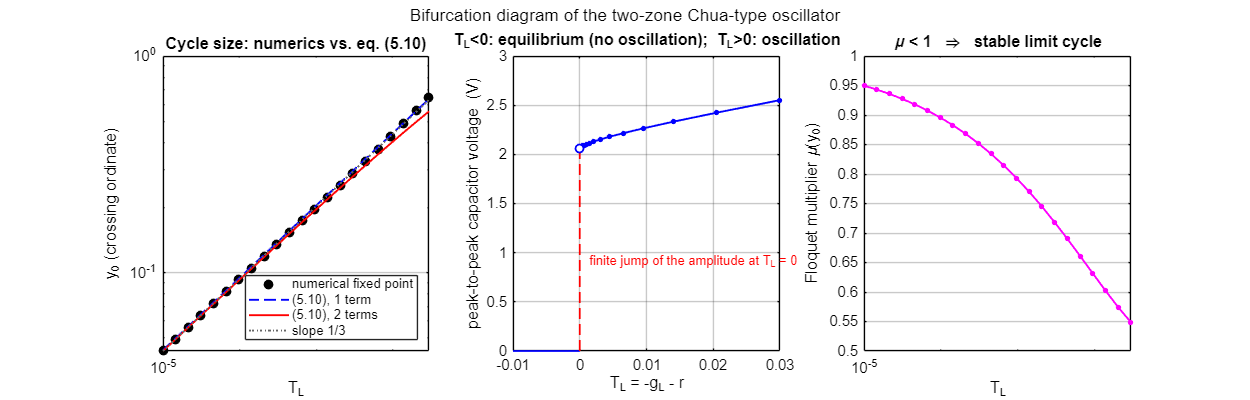

In [5]:
%% 3c-ii.  Bifurcation diagram: size, period and stability of the limit cycle as TL crosses 0
mkp  = @(TL) struct('TL',TL, 'DL',DL_of_TL(TL), 'TR',TR, 'DR',DR, 'a',a);
opts = odeset('RelTol',1e-10,'AbsTol',1e-12);

TLg  = logspace(-5, log10(3e-2), 22);          % values of TL > 0
[y0_n, y0_a, y0_b, mus, Tper, vpp] = deal(nan(size(TLg)));
for k = 1:numel(TLg)
    pk = mkp(TLg(k));
    y0_b(k) = y0_1term(TLg(k));   y0_a(k) = y0_2term(TLg(k));        % theory, eq. (5.10)
    lo = 0.5*y0_a(k);  hi = 1.6*y0_a(k);                                % bracket around the theoretical value
    while gap(lo,pk)*gap(hi,pk) > 0, lo = 0.7*lo;  hi = 1.3*hi; end
    y0_n(k) = fzero(@(y) gap(y,pk), [lo hi]);                           % exact fixed point of the return map
    [~, ~, tauL, tauR] = retmap(y0_n(k), pk);
    mus(k)  = exp(pk.TL*tauL + pk.TR*tauR);   Tper(k) = tauL + tauR;
    [~,X]   = ode45(@(t,X) lienard(t,X,pk), [0 Tper(k)], [0; y0_n(k)], opts);
    vpp(k)  = Vb*(max(X(:,1)) - min(X(:,1)));                           % peak-to-peak capacitor voltage
end

fprintf('   TL         y0 numerical   y0 (5.10)   rel.err(%%)   Floquet mu    T (sqrt(LC))   f (kHz)   Vpp (V)\n');
for k = 1:3:numel(TLg)
    fprintf('%9.2e   %10.5f    %9.5f    %7.2f      %8.5f     %9.5f    %7.3f   %7.3f\n', TLg(k), y0_n(k), y0_a(k), ...
            100*abs(y0_a(k)-y0_n(k))/y0_n(k), mus(k), Tper(k), 1e-3/(Tper(k)*tau0), vpp(k));
end
% slope of log(y0) versus log(TL): the TL^(1/3) law of Theorem 5.1
slope = polyfit(log(TLg(1:8)), log(y0_n(1:8)), 1);
fprintf('\nFitted exponent of y0 ~ TL^s for the smallest TL values: s = %.3f  (theory: 1/3)\n', slope(1));

%% Figure 4 -- bifurcation diagram
figure('Position',[50 50 1250 400]);
subplot(1,3,1);
loglog(TLg, y0_n, 'ko', 'MarkerFaceColor','k');  hold on;  grid on;
loglog(TLg, y0_b, 'b--');  loglog(TLg, y0_a, 'r-');
loglog(TLg, y0_n(1)*(TLg/TLg(1)).^(1/3), ':', 'Color',[.4 .4 .4]);
xlabel('T_L'); ylabel('y_0 (crossing ordinate)');  title('Cycle size: numerics vs. eq. (5.10)');
legend('numerical fixed point','(5.10), 1 term','(5.10), 2 terms','slope 1/3','Location','southeast');

subplot(1,3,2);
plot(TLg, vpp, 'b.-', 'MarkerSize', 12);  hold on;  grid on;
plot([-0.01 0], [0 0], 'b-', 'LineWidth', 1.4);                     % TL<0: only the (stable) equilibrium
plot([0 0], [0 vpp(1)], 'r--');  plot(0, vpp(1), 'bo', 'MarkerFaceColor', 'w');
text(0.0012, 0.9, 'finite jump of the amplitude at T_L = 0', 'Color', 'r');
xlabel('T_L = -g_L - r'); ylabel('peak-to-peak capacitor voltage  (V)');  ylim([0 3]);
title('T_L<0: equilibrium (no oscillation);  T_L>0: oscillation');

subplot(1,3,3);
semilogx(TLg, mus, 'm.-', 'MarkerSize', 12);  hold on;  grid on;  yline(1,'k--');
xlabel('T_L'); ylabel('Floquet multiplier \mu(y_0)');  title('\mu < 1  \Rightarrow  stable limit cycle');
sgtitle('Bifurcation diagram of the two-zone Chua-type oscillator', 'Color', 'k');

%% ---------------- local functions (must stay at the end of the cell) ----------------
function g = gap(y, p)                  % P(y) - y ; "no return" means the orbit contracts, so count it as negative
    yn = retmap(y, p);   if isnan(yn), g = -1; else, g = yn - y; end
end
function dX = lienard(~, X, p)          % Lienard canonical form (5.1)
    if X(1) <= 0, T = p.TL; D = p.DL; else, T = p.TR; D = p.DR; end
    dX = [T*X(1) - X(2);  D*X(1) - p.a];
end
function [val, term, dir] = evline(~, X, xl, d)
    val = X(1) - xl;  term = 1;  dir = d;
end
function [y0n, y1, tauL, tauR] = retmap(y0, p)    % one full turn: (0,y0) -> (0,y1) -> (0,y0n)
    f  = @(t,X) lienard(t,X,p);
    oU = odeset('RelTol',1e-12,'AbsTol',1e-14,'Events',@(t,X) evline(t,X,0,+1));
    oD = odeset('RelTol',1e-12,'AbsTol',1e-14,'Events',@(t,X) evline(t,X,0,-1));
    y0n = NaN; y1 = NaN; tauL = NaN; tauR = NaN;
    [~,~,te,Xe] = ode45(f,[0 200],[0;y0],oU);  if isempty(te), return; end
    tauL = te(1);  y1 = Xe(1,2);
    [~,~,te,Xe] = ode45(f,[0 200],[0;y1],oD);  if isempty(te), return; end
    tauR = te(1);  y0n = Xe(1,2);
end


### 3d. Discussion of the results (System 1)

* **Canonical form.** The change of variables of Proposition 3.3 reduces the circuit, which has 5 parameters $(r,g_L,g_R,u_b,c_b)$, to the 5 numbers $(T_L,D_L,T_R,D_R,a)$ of (3.8), and the numerical check confirms it is an exact conjugacy (mismatch $\sim10^{-15}$). In these variables the three hypotheses of Theorem 5.1 are directly readable: $a=-1.02<0$, $T_R=-0.6<0$ and $T_L\in(-2\sqrt{D_L},2\sqrt{D_L})$. The bifurcation parameter is $T_L=-g_L-r$: it vanishes when the negative conductance of the diode, $g_L=-r$ ($G_{in}=-0.247$ mS), exactly compensates the coil resistance.
* **Figure 1 (cf. Figure 3.3 of the thesis).** For $T_L<0$ the orbit spirals into the focus. For $T_L=0$ the inner zone is a centre: the grey ellipses are closed orbits, and the green one is the ellipse tangent to $\{x=0\}$ with $y^2+D_Lx^2-2ax=0$. Orbits that cross to the right zone lose energy ($T_R<0$) and are attracted to this tangent ellipse; this is the "limit" that the cycle will inherit. For $T_L=10^{-3}>0$ there is a stable limit cycle (dashed magenta) that lies very close to the tangent ellipse; orbits started inside and outside converge to it.
* **Quality of formula (5.10).** For $T_L=10^{-3}$ the theoretical ordinate is $y_0^*=0.1956$ against the exact fixed point $0.1987$ (error $1.6\,\%$); the error decreases with $T_L$ (0.07 % at $T_L=10^{-5}$) and grows to $\approx14\,\%$ at $T_L=0.03$, as expected from a series in $T_L^{1/3}$ truncated after two terms. Starting at the theoretical value and iterating the return map, the sequence $0.19564,\,0.19629,\,0.19680,\dots$ converges monotonically to $0.19873$: the cobweb of Figure 2 (right) shows a *stable* fixed point of $P$.
* **Other predictions of Theorem 5.1** are confirmed to high accuracy: $y_1$ from the series matches the numerical value to 5 digits, the period computed by simulation and by the integral formula agree to 6 digits ($T=6.31487$ in units of $\sqrt{LC}$, i.e. $\approx 281\;\mu$s or $3.56$ kHz), and the Floquet multiplier from $e^{T_L\tau_L+T_R\tau_R}$ coincides with the finite-difference derivative of $P$ ($\mu=0.7912<1$, so the cycle is stable, as proved in Section 5.3 via (5.9)).
* **Bifurcation diagram (Figure 4).** The size of the cycle scales as $y_0\sim T_L^{1/3}$ (fitted exponent $0.330$ vs. $1/3$), so the cycle appears with infinite slope in $y_0$. In physical terms the voltage amplitude **jumps from $0$ to $\approx2.06$ V** as soon as $T_L>0$ and then grows slowly; the multiplier is always $<1$ (stable) and tends to $1$ as $T_L\to0^+$. The oscillation frequency is essentially constant ($\approx3.56$ kHz), set by the LC tank.
* **Engineering reading.** The thesis formulas give the *threshold* of oscillation ($g_L=-r$, i.e. a precise value of the diode conductance), the *stability* of the oscillation (via $T_R<0$) and a good estimate of its amplitude and period, without integrating the system.

---
## 4. System 2 — McKean model: saddle-node bifurcation of periodic orbits (Chapters 3 and 6)

### 4a. Transformation to the normalised form (Propositions 3.5 and 3.6)

The McKean system has the form (3.12) with thresholds $v=0,\,w=1$ (we write $\theta_1=0,\theta_2=1$ to avoid confusion with the state variables), $M_k=\begin{pmatrix}s_k/\varepsilon&-1/\varepsilon\\1&-\gamma\end{pmatrix}$ and $n_L=n_C=(I/\varepsilon,0)^t$, $n_R=((I+s_C-s_R)/\varepsilon,0)^t$ (for $s_C=a-1$, $s_R=-1$ this is exactly Example 3.2). Since $m^L_{12}=m^C_{12}=m^R_{12}=-1/\varepsilon\ne0$ we can apply

* **Proposition 3.5**: $(X,Y)^t=Px+c$ with $P=\begin{pmatrix}\frac{2}{\theta_2-\theta_1}&0\\-\frac{2m_{22}}{\theta_2-\theta_1}&\frac{2m_{12}}{\theta_2-\theta_1}\end{pmatrix}$, $c=\frac{\theta_1+\theta_2}{\theta_2-\theta_1}\begin{pmatrix}-1\\m_{22}\end{pmatrix}$, which sends the separation lines to $X=\pm1$ and gives $N_k=\begin{pmatrix}T_k&1\\-D_k&0\end{pmatrix}$, $d_k=Pn_k-N_kc$;
* **Proposition 3.6** (needs $D_C>0$): rescales time, $t=\sqrt{D_C}\,s$, and shifts $y$, producing system (3.14)/(6.1) with
$t_{L,R}=T_{L,R}/\sqrt{D_C}$, $d_{L,R}=D_{L,R}/D_C$, $m=-T_C/\sqrt{D_C}$ and $a_C$.

The cell prints all matrices and vectors for both models, **verifies** the transformation by integrating the physical system and the normalised one along an orbit that visits the three zones, and tests the hypotheses of Theorem 6.2.

> **Remark on $a_C$.** The equilibrium of the central zone of (3.14) is $(a_C,0)$. Writing $y(t)=\frac{1}{\sqrt{D_C}}\big(Y+(1,T_C/D_C)\cdot d_C\big)$ one finds $a_C=(d_C)_2/D_C$, which coincides with the abscissa of the equilibrium, $a_C=2v^*-1$ (checked in the cell). Proposition 3.6 writes $a_C=(0,1)\cdot d_C$, which is the same number only when $D_C=1$; the numerical check (second to last line of each block) uses $(d_C)_2/D_C$.

In [6]:
%% 4a.  McKean caricature: matrices, and the changes of variables of Propositions 3.5 and 3.6
clearvars;  close all;
epsm = 1.0;      % time-scale parameter epsilon
gam  = 0.5;      % recovery rate gamma
Iapp = 0.30;     % applied current (only used here to display the matrices and to test the change of variables)
th   = [0 1];    % thresholds v = 0 and v = 1  (the role of "v,w" in Proposition 3.5)

% f(v) = sL*v  (v<=0),  sC*v  (0<v<=1),  sC + sR*(v-1)  (v>1).   Thesis, Example 3.2:  sL = -1, sC = a-1, sR = -1.
models(1).name = 'Standard McKean (thesis Example 3.2 with a = 1.5)';   models(1).s = [-1 0.5 -1];
models(2).name = 'Asymmetric McKean (outer-right slope +1)';           models(2).s = [-1 0.5 +1];

zone3 = @(x) 1*(x<=-1) + 2*(x>-1 & x<=1) + 3*(x>1);            % zone index of the normalised system
for k = 1:2
    s = models(k).s;
    % ---- original system  x' = M_k x + n_k  (x = (v,w)) ---------------------------------
    Mk = @(sk) [sk/epsm, -1/epsm;  1, -gam];
    M  = {Mk(s(1)), Mk(s(2)), Mk(s(3))};
    n  = {[Iapp;0]/epsm, [Iapp;0]/epsm, [Iapp + s(2) - s(3); 0]/epsm};
    fprintf('\n=================  %s  =================\n', models(k).name);
    fprintf('Slopes of f: sL = %+g, sC = %+g, sR = %+g   (epsilon = %g, gamma = %g, I = %g)\n', s, epsm, gam, Iapp);
    disp('M_L ='); disp(M{1});  disp('M_C ='); disp(M{2});  disp('M_R ='); disp(M{3});
    disp('n_L = n_C = (I/eps, 0)^T,   n_R ='); disp(n{3});

    % ---- Proposition 3.5:  (X,Y)^T = P x + c,  N_k = [T_k 1; -D_k 0],  d_k = P n_k - N_k c -------
    m12 = M{2}(1,2);  m22 = M{2}(2,2);
    P = [2/(th(2)-th(1)), 0;  -2*m22/(th(2)-th(1)), 2*m12/(th(2)-th(1))];
    c = (th(1)+th(2))/(th(2)-th(1)) * [-1; m22];
    T = zeros(1,3);  D = zeros(1,3);  N = cell(1,3);  d = cell(1,3);
    for j = 1:3
        T(j) = trace(M{j});  D(j) = det(M{j});
        N{j} = [T(j) 1; -D(j) 0];   d{j} = P*n{j} - N{j}*c;
    end
    disp('--- Proposition 3.5 ---');  disp('P ='); disp(P);  disp('c ='); disp(c);
    fprintf('T_k = [%.4f %.4f %.4f],  D_k = [%.4f %.4f %.4f]\n', T, D);
    disp('d_L ='); disp(d{1});  disp('d_C ='); disp(d{2});  disp('d_R ='); disp(d{3});

    % ---- Proposition 3.6 (needs D_C > 0):  scaling of time and shift of y -------------------------------
    DC = D(2);  TC = T(2);
    tL = T(1)/sqrt(DC);  dL = D(1)/DC;  tR = T(3)/sqrt(DC);  dR = D(3)/DC;  m = -TC/sqrt(DC) + 0;     % (+0 avoids printing "-0")
    aC = d{2}(2)/DC;                 % abscissa of the equilibrium of the central zone, see the remark below
    AL = [tL 1; -dL 0];  AC = [-m 1; -1 0];  AR = [tR 1; -dR 0];
    bL = [tL + m*(aC+1);  aC + 1 - dL];   bC = [m*aC; aC];   bR = [m*(aC-1) - tR;  aC - 1 + dR];
    disp('--- Proposition 3.6: normalised system (3.14) ---');
    fprintf('tL = %.4f, dL = %.4f, tR = %.4f, dR = %.4f, m = %.4f, aC = %.4f\n', tL, dL, tR, dR, m, aC);
    disp('A_L ='); disp(AL);  disp('A_C ='); disp(AC);  disp('A_R ='); disp(AR);
    disp('b_L ='); disp(bL);  disp('b_C ='); disp(bC);  disp('b_R ='); disp(bR);
    vstar = Iapp*gam/(1 - gam*s(2));
    fprintf('Check of the remark: equilibrium abscissa 2v*-1 = %.4f = d_C(2)/D_C = %.4f  (but (0,1).d_C = %.4f)\n', ...
            2*vstar-1, aC, d{2}(2));

    % ---- numerical verification: physical flow versus normalised flow along an orbit visiting L, C and R ----
    AA = cat(3, AL, AC, AR);   BB = [bL, bC, bR];
    fnorm = @(t,Z) AA(:,:,zone3(Z(1)))*Z + BB(:,zone3(Z(1)));
    fv    = @(v) (v<=0)*s(1)*v + (v>0 & v<=1)*s(2)*v + (v>1)*(s(2) + s(3)*(v-1));
    fphys = @(t,X) [(fv(X(1)) - X(2) + Iapp)/epsm;  X(1) - gam*X(2)];
    tt = linspace(0, 6, 61);   o = odeset('RelTol',1e-12,'AbsTol',1e-13);
    X0 = [1.6; 0.9];
    [~,Xp] = ode45(fphys, tt, X0, o);                                     % physical time s
    Xn0 = P*X0 + c;  Z0 = [Xn0(1); (Xn0(2) + [1 TC/DC]*d{2})/sqrt(DC)];
    [~,Zn] = ode45(fnorm, sqrt(DC)*tt, Z0, o);                            % normalised time t = sqrt(DC)*s
    err = 0;
    for j = 1:numel(tt)
        Xn = P*Xp(j,:)' + c;  Zm = [Xn(1); (Xn(2) + [1 TC/DC]*d{2})/sqrt(DC)];
        err = max(err, norm(Zm - Zn(j,:)'));
    end
    fprintf('Orbit visits  L: %d  C: %d  R: %d  -> max |mapped physical orbit - normalised orbit| = %.1e\n', ...
            any(Xp(:,1)<=0), any(Xp(:,1)>0 & Xp(:,1)<=1), any(Xp(:,1)>1), err);

    % ---- hypotheses of Theorems 6.1 / 6.2 ----------------------------------------------------
    sigma = tL*tR*(tL^2 - tR^2);
    fprintf('Hypotheses:  tL*tR = %+.4f (<0 needed): %d | tL+tR = %+.4f (~=0 needed): %d | |m|<2: %d | |aC|<1: %d | sigma = %+.4f\n', ...
            tL*tR, tL*tR<0, tL+tR, abs(tL+tR)>1e-12, abs(m)<2, abs(aC)<1, sigma);
    if tL*tR >= 0, disp('  --> tL*tR >= 0: Theorem 6.2 can NOT be applied to this system.');
    else,          disp('  --> hypotheses of Theorem 6.2 are satisfied.');  end
end


Standard McKean (thesis Example 3.2 with a = 1.5)

Slopes of f: sL = 

-1

, sC = 

+0.5

...

 | |aC|<1: 

1

 | sigma = 

-2.6667

  --> hypotheses of Theorem 6.2 are satisfied.


**Result of the check.** For the standard model $t_L=t_R=-\sqrt3$, so $t_Lt_R>0$: **Theorem 6.2 cannot be applied** (and $\sigma=t_Lt_R(t_L^2-t_R^2)=0$ as well). For the asymmetric model $t_L=-\sqrt3$, $t_R=1/\sqrt3$, $d_L=2$, $d_R=2/3$: $t_Lt_R=-1<0$, $t_L+t_R\neq0$ and $\sigma=-8/3<0$. Both models share the same central zone, and with $s_C=\varepsilon\gamma=0.5$ we are exactly at $m=0$.

### 4b. Initial values from the theory (Lemma 6.1 and Theorem 6.2)

Theorem 6.2 gives, for $m\,t_R(t_L^2-t_R^2)>0$ (here $m>0$), the bifurcation curve (6.19) and the ordinate of the semi-stable cycle (6.20) (leading terms)
$$a_C^*(m)=\Big(\tfrac{3\pi}{16}\Big)^{2/3}\Big(\tfrac1{t_R^2}-\tfrac1{t_L^2}\Big)^{1/3}m^{2/3}+\mathcal O(m),\qquad y_0^*(m)=\Big(\tfrac{3\pi t_R^2}{2t_L(t_R^2-t_L^2)}\Big)^{1/3}m^{1/3}+\mathcal O(m^{2/3}),$$
and the period (6.21), $T=2\pi+\frac{(1-d_R)t_L^3+(d_L-1)t_R^3}{t_Lt_R(t_L^2-t_R^2)}\pi m+\mathcal O(m^{4/3})$. Lemma 6.1, eq. (6.18), gives the whole periodic orbit through $(-1,y_0)\to(1,y_1)\to(1,y_2)\to(-1,y_3)$ and a parametrisation $\big(m^*(y_0),a_C^*(y_0)\big)$ of the curve; we use
$m^*=-\frac{2(t_L^3-t_Lt_R^2)}{3\pi t_R^2}y_0^3$, $a_C^*=-\frac{t_R^2-t_L^2}{4t_R^2}y_0^2-\frac{t_L^3-t_Lt_R^2}{6t_R^2}y_0^3$, $y_1^*=-\frac{t_L}{t_R}y_0$, $y_2^*=\frac{t_L}{t_R}y_0-\frac{2t_L^2}{3t_R}y_0^2$, $y_3^*=-y_0+\frac{2t_L}{3}y_0^2$.

**How the physical parameters enter.** We keep $\varepsilon,\gamma,s_L,s_R$ fixed and use $s_C$ to tune $m$ (since $m=-(s_C/\varepsilon-\gamma)/\sqrt{(1-\gamma s_C)/\varepsilon}$, $m=0\iff s_C=\varepsilon\gamma$) and the applied current $I$ to tune $a_C$: from the equilibrium of the central zone, $v^*=\gamma I/(1-\gamma s_C)$ and $a_C=2v^*-1$, so $I=\frac{(1+a_C)(1-\gamma s_C)}{2\gamma}$. The coefficients $t_L,t_R,d_L,d_R$ depend on $s_C$ only through $D_C$ and are recomputed for each $m$ (they change by less than 1 %).

In [7]:
%% 4b.  Initial values predicted by Theorem 6.2:  aC*(m)  (6.19),  y0*(m)  (6.20),  Lemma 6.1 (6.18),  period (6.21)
% Parameters of the asymmetric McKean model that stay fixed while (m, aC) move.
% m is tuned through the central slope sC, aC through the applied current I.  Both enter the normalised
% coefficients tL, tR, dL, dR only through D_C, so they are recomputed for every m ("exact" values).
epsm = 1.0;  gam = 0.5;  sL = -1;  sR = +1;                 % fixed physical parameters
Tk = @(s) s/epsm - gam;                                     % trace of the zone with slope s
Dk = @(s) (1 - gam*s)/epsm;                                 % determinant of the zone with slope s
mfun    = @(sC) -Tk(sC)./sqrt(Dk(sC));                      % m = -T_C/sqrt(D_C)
sC_of_m = @(m) fzero(@(s) mfun(s) - m, epsm*gam);           % invert it (m = 0  <=>  sC = eps*gamma)
coef    = @(sC) deal(Tk(sL)/sqrt(Dk(sC)), Tk(sR)/sqrt(Dk(sC)), Dk(sL)/Dk(sC), Dk(sR)/Dk(sC));   % tL,tR,dL,dR
I_of_aC = @(aC,sC) (1 + aC).*(1 - gam*sC)/(2*gam);          % applied current giving the equilibrium abscissa aC

% ---- the formulas of the thesis -------------------------------------------------------------------------
aC_formula = @(m,tL,tR) (3*pi/16)^(2/3) * nthroot(1/tR^2 - 1/tL^2, 3) .* m.^(2/3);                 % (6.19), leading term
y0_formula = @(m,tL,tR) nthroot(3*pi*tR^2/(2*tL*(tR^2 - tL^2)), 3) .* m.^(1/3);                     % (6.20), leading term
% Lemma 6.1, eq. (6.18): parametrisation of the bifurcation curve by y0 (terms up to the order shown there)
m_lemma  = @(y0,tL,tR) -2*(tL^3 - tL*tR^2)/(3*pi*tR^2) .* y0.^3;
aC_lemma = @(y0,tL,tR) -(-tL^2 + tR^2)/(4*tR^2) .* y0.^2 - (tL^3 - tL*tR^2)/(6*tR^2) .* y0.^3;
y1_lemma = @(y0,tL,tR) -(tL/tR) .* y0;                                        % + O(y0^3)
y2_lemma = @(y0,tL,tR)  (tL/tR) .* y0 - 2*tL^2/(3*tR) .* y0.^2;              % + O(y0^3)  (printed form of y2*)
y3_lemma = @(y0,tL,tR) -y0 + 2*tL/3 .* y0.^2;                                % + O(y0^3)
T_formula = @(m,tL,dL,tR,dR) 2*pi + ((1-dR)*tL^3 + (dL-1)*tR^3)/(tL*tR*(tL^2 - tR^2)) * pi * m;     % (6.21)

mgrid = [1e-4 1e-3 3e-3 1e-2 3e-2];
fprintf('Sign of  m*tR*(tL^2-tR^2)  must be positive.  Asymmetric McKean, eps = %g, gamma = %g, sL = %g, sR = %g\n\n', epsm, gam, sL, sR);
fprintf('    m         sC       tL       tR      sigma     y0*(6.20)   aC*(6.19)   aC*(6.18)   I*(6.19)   T (6.21)\n');
for k = 1:numel(mgrid)
    m = mgrid(k);  sC = sC_of_m(m);  [tL,tR,dL,dR] = coef(sC);  sigma = tL*tR*(tL^2 - tR^2);
    y0s = y0_formula(m,tL,tR);  aCs = aC_formula(m,tL,tR);
    y0b = fzero(@(y) m_lemma(y,tL,tR) - m, y0s);                       % y0 such that m*(y0) = m  (Lemma 6.1)
    fprintf('%8.1e  %8.5f  %7.4f  %7.4f  %7.3f   %9.5f   %9.5f   %9.5f   %8.5f   %8.5f\n', m, sC, tL, tR, sigma, ...
            y0s, aCs, aC_lemma(y0b,tL,tR), I_of_aC(aCs,sC), T_formula(m,tL,dL,tR,dR));
end
m0 = 1e-2;  sC0 = sC_of_m(m0);  [tL,tR,dL,dR] = coef(sC0);  y00 = y0_formula(m0,tL,tR);
fprintf('\nFull set of initial values for the periodic orbit at m = %g, aC = aC*(m):\n', m0);
fprintf('   (-1,y0) = (-1, %.5f),  y1 = %.5f,  y2 = %.5f,  y3 = %.5f   [Lemma 6.1, leading terms]\n', ...
        y00, y1_lemma(y00,tL,tR), y2_lemma(y00,tL,tR), y3_lemma(y00,tL,tR));


Sign of  m*tR*(tL^2-tR^2)  must be positive.  Asymmetric McKean, eps = 

1

, gamma = 

0.5

, sL = 

...

,  y2 = 

-0.52985

,  y3 = 

-0.17662

   [Lemma 6.1, leading terms]


### 4c. Simulation of the bifurcation

The normalised system (6.1) is simulated with `ode45`. The Poincaré map of the line $\{x=-1\}$ is the composition $P=P_L\circ P_{C_D}\circ P_R\circ P_{C_U}$ of (6.10); it is computed numerically by following the four legs $(-1,y_0)\to(1,y_1)\to(1,y_2)\to(-1,y_3)\to(-1,y_0')$ with event detection, and the Floquet multiplier of a periodic orbit is the exponential of the integral of the divergence, $\mu=\exp\big(-m(\tau_{C_U}+\tau_{C_D})+t_R\tau_R+t_L\tau_L\big)$ (the divergence is $-m$, $t_R$ and $t_L$ in the zones $C$, $R$, $L$).

The first cell:

1. refines the thesis formulas: starting from (6.20) and (6.18) it solves *simultaneously* $P(y)=y$ and $P'(y)=1$ (the non-hyperbolicity equation (6.12)) by Newton's method, to measure the accuracy of the leading-order formulas;
2. shows the three scenarios of Theorem 6.2 for $m=0.01$ (no cycle / semi-stable cycle / two cycles) through the graph of $P(y)-y$ and through phase portraits (cf. Figure 6.3);
3. draws the bifurcation curve in the $(m,a_C)$ plane (cf. Figure 3.4) and the saddle-node diagram at fixed $m$ with the Floquet multipliers of both cycles;
4. contrasts with the **standard** McKean model ($t_L=t_R$), where no pair of cycles appears.

The second cell goes back to the physical variables $(v,w)$ using the inverse of Propositions 3.5–3.6.

    m       aC fold (num)   aC (6.19)  err

%

    aC (6.18)  err

%

    y0 fold (num)  y0 (6.20)   T (num)   T (6.21)


...

0.04875

 (

sigma(aC - aC*) < 0 : two limit cycles

): fixed points y0 = 

[0.04786 0.1779]

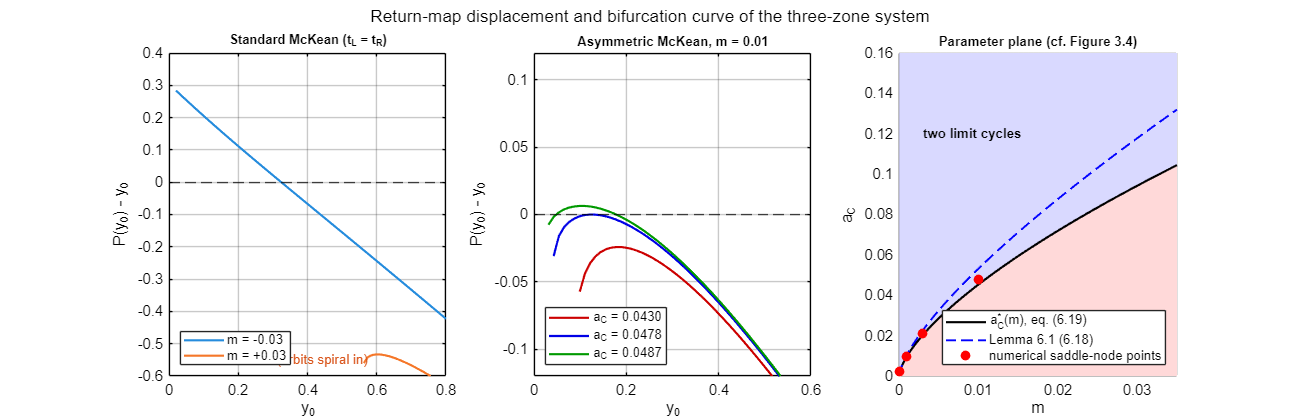

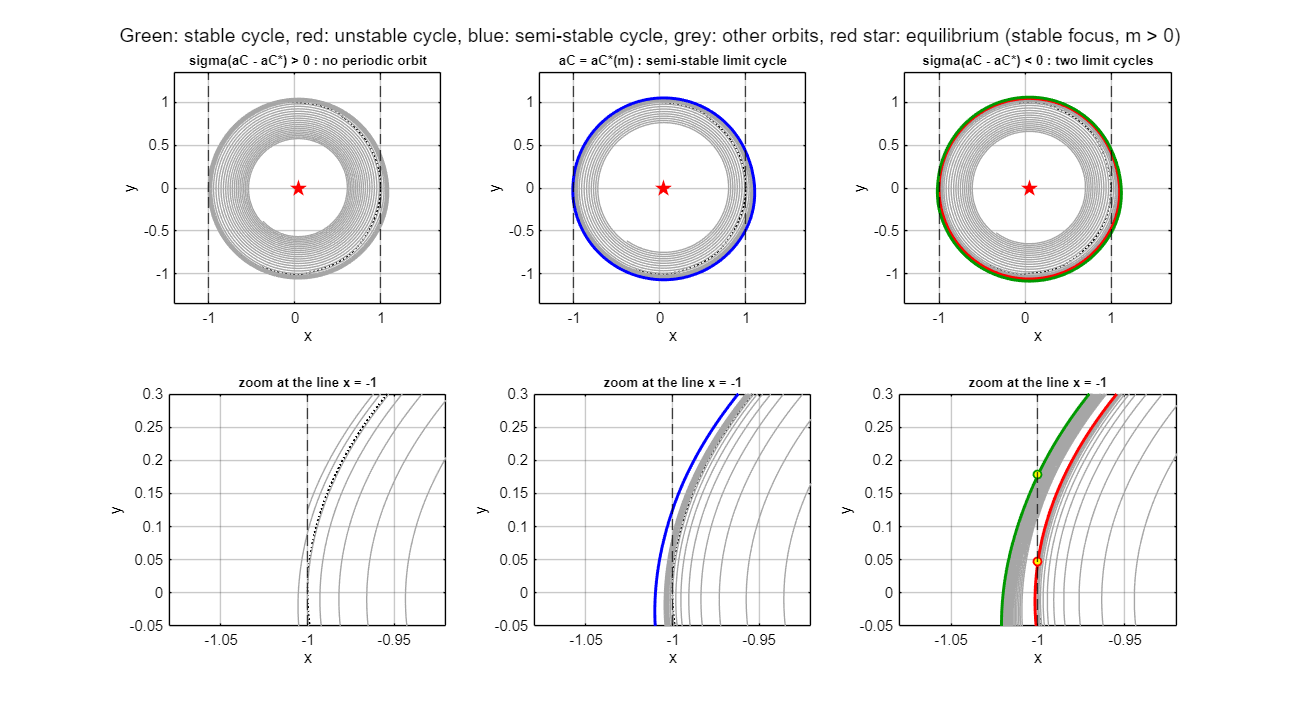

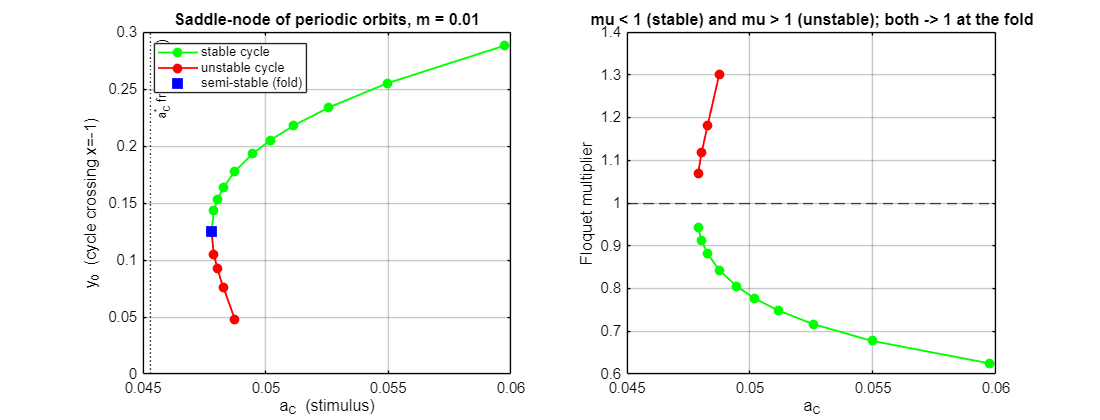

In [8]:
%% 4c-i.  Numerical study of the saddle-node bifurcation of periodic orbits (normalised system (6.1))
% Uses epsm, gam, sL, sR and the handles Tk, Dk, coef, sC_of_m, I_of_aC, aC_formula, y0_formula, aC_lemma, m_lemma,
% T_formula created in the previous cell.
mk = @(m) struct('tL',coef_k(coef,sC_of_m(m),1), 'tR',coef_k(coef,sC_of_m(m),2), ...
                 'dL',coef_k(coef,sC_of_m(m),3), 'dR',coef_k(coef,sC_of_m(m),4));

%% (1) Non-hyperbolic orbits: solve  P(y)=y  and  P'(y)=1  simultaneously (Newton) starting from the thesis formulas
mlist = [1e-4 1e-3 3e-3 1e-2];
fprintf('    m       aC fold (num)   aC (6.19)  err%%    aC (6.18)  err%%    y0 fold (num)  y0 (6.20)   T (num)   T (6.21)\n');
fold = struct('m',{},'aC',{},'y0',{});
for k = 1:numel(mlist)
    m = mlist(k);  p = mk(m);
    y0g = y0_formula(m,p.tL,p.tR);                               % (6.20)
    y0l = fzero(@(y) m_lemma(y,p.tL,p.tR) - m, y0g);             % Lemma 6.1
    aCg = aC_lemma(y0l,p.tL,p.tR);                               % (6.18)
    [yf, aCf, ok] = foldpoint(m, p, y0g, aCg);
    [~, ~, tt] = retmap3(yf, m, aCf, p);
    fold(k) = struct('m',m,'aC',aCf,'y0',yf);
    fprintf('%8.1e    %10.6f    %9.6f  %5.1f   %9.6f  %5.1f      %9.5f     %9.5f   %8.5f  %8.5f %s\n', m, aCf, ...
        aC_formula(m,p.tL,p.tR), 100*abs(aC_formula(m,p.tL,p.tR)/aCf-1), aCg, 100*abs(aCg/aCf-1), yf, y0g, ...
        sum(tt), T_formula(m,p.tL,p.dL,p.tR,p.dR), repmat('(Newton failed)',1,~ok));
end
fprintf('The relative error of (6.19) decreases as m -> 0 (it is a leading-order term, error O(m^(1/3))).\n');

%% (2) The three scenarios of Theorem 6.2 for m = m_demo
m_demo = 1e-2;  p = mk(m_demo);  sigma = p.tL*p.tR*(p.tL^2 - p.tR^2);
[yf, aCf] = deal(fold(4).y0, fold(4).aC);                        % numerical fold at m = 1e-2
scen = [0.9, 1.0, 1.02]*aCf;
names = {'sigma(aC - aC*) > 0 : no periodic orbit', 'aC = aC*(m) : semi-stable limit cycle', 'sigma(aC - aC*) < 0 : two limit cycles'};
if sigma > 0, scen = fliplr(scen); end                           % keep "none / fold / two" in this order
fprintf('\nm = %g, sigma = %.3f:  fold at aC = %.5f (numerical), formula (6.19) gives %.5f\n', m_demo, sigma, aCf, aC_formula(m_demo,p.tL,p.tR));
roots = cell(1,3);
for k = 1:3
    g = @(y) gap3(y, m_demo, scen(k), p);
    if k == 1                                                    % below the curve: P(y)-y < 0 everywhere
        fprintf('  aC = %.5f (%s): max over y of P(y)-y = %.2e < 0  -> no fixed point\n', scen(k), names{k}, max(arrayfun(g, linspace(0.02,0.5,30))));
    elseif k == 2
        roots{k} = yf;
        fprintf('  aC = %.5f (%s): double fixed point y0 = %.5f\n', scen(k), names{k}, yf);
    else                                                         % above: one root on each side of the fold ordinate
        hi = 1.5*yf;  while g(hi) > 0, hi = 1.5*hi; end
        lo = 0.7*yf;  while g(lo) > 0 && lo > 1e-4, lo = 0.7*lo; end
        roots{k} = [fzero(g,[lo yf]), fzero(g,[yf hi])];
        fprintf('  aC = %.5f (%s): fixed points y0 = %s\n', scen(k), names{k}, mat2str(roots{k},4));
    end
end

%% Figure 5 -- return-map displacement P(y)-y, and the bifurcation diagram in the (m, aC) plane
yy = linspace(0.02, 0.8, 70);   figure('Position',[50 50 1300 420]);
subplot(1,3,1);  hold on;  grid on;                              % standard McKean: tL = tR
pstd = struct('tL',p.tL,'tR',p.tL,'dL',p.dL,'dR',p.dL);
for mm = [-0.03 0.03]
    gg = arrayfun(@(y) retmap3(y,mm,0,pstd) - y, yy);  plot(yy, gg, 'LineWidth', 1.6, 'DisplayName', sprintf('m = %+.2f', mm));
end
yline(0,'k--','HandleVisibility','off');  xlabel('y_0');  ylabel('P(y_0) - y_0');  ylim([-0.6 0.4]);  legend('Location','southwest');
title('Standard McKean (t_L = t_R)', 'FontSize', 10);
text(0.05, -0.55, 'm>0: no return (orbits spiral in)', 'Color', [.85 .33 .1]);

subplot(1,3,2);  hold on;  grid on;                              % asymmetric: two roots / tangency / none
cols = {[.8 0 0], [0 0 .9], [0 .6 0]};
for k = 1:3
    gg = arrayfun(@(y) retmap3(y,m_demo,scen(k),p) - y, yy);  plot(yy, gg, 'Color', cols{k}, 'LineWidth', 1.6, ...
        'DisplayName', sprintf('a_C = %.4f', scen(k)));
end
yline(0,'k--','HandleVisibility','off');  xlabel('y_0');  ylabel('P(y_0) - y_0');  ylim([-0.12 0.12]);  legend('Location','southwest');
title(sprintf('Asymmetric McKean, m = %g', m_demo), 'FontSize', 10);

subplot(1,3,3);  hold on;  grid on;                              % bifurcation curve and regions
mm = linspace(1e-5, 0.035, 200);
curve19 = aC_formula(mm, p.tL, p.tR);   y0m = arrayfun(@(m) fzero(@(y) m_lemma(y,p.tL,p.tR)-m, y0_formula(m,p.tL,p.tR)), mm);
curve18 = aC_lemma(y0m, p.tL, p.tR);
top = 0.16;  sgn = sign(sigma);
if sgn < 0, fill([mm fliplr(mm)], [curve19 top*ones(size(mm))], [.85 .85 1], 'EdgeColor','none');   % two cycles above
            fill([mm fliplr(mm)], [curve19 zeros(size(mm))],    [1 .85 .85], 'EdgeColor','none');   % none below
else,       fill([mm fliplr(mm)], [curve19 zeros(size(mm))],    [.85 .85 1], 'EdgeColor','none');
            fill([mm fliplr(mm)], [curve19 top*ones(size(mm))], [1 .85 .85], 'EdgeColor','none'); end
h1 = plot(mm, curve19, 'k-', 'LineWidth', 1.6);  h2 = plot(mm, curve18, 'b--', 'LineWidth', 1.4);
h3 = plot([fold.m], [fold.aC], 'ro', 'MarkerFaceColor', 'r');
text(0.003, 0.12, 'two limit cycles', 'FontWeight', 'bold');  text(0.018, 0.02, 'no limit cycle', 'FontWeight', 'bold');
xlabel('m');  ylabel('a_C');  xlim([0 0.035]);  ylim([0 top]);
legend([h1 h2 h3], {'a_C^*(m), eq. (6.19)', 'Lemma 6.1 (6.18)', 'numerical saddle-node points'}, 'Location', 'southeast');
title('Parameter plane (cf. Figure 3.4)', 'FontSize', 10);
sgtitle('Return-map displacement and bifurcation curve of the three-zone system', 'Color', 'k');

%% Figure 6 -- phase portraits of the three scenarios (cf. Figure 6.3), normalised coordinates; second row: zoom at x = -1
opts = odeset('RelTol',1e-10,'AbsTol',1e-12);
traj = cell(1,3);                                                  % trajectories: {grey spirals, coloured cycles}
for k = 1:3
    f = @(t,Z) field3(Z,m_demo,scen(k),p);
    switch k
        case 1                                                     % no cycle: orbits spiral in to the stable focus
            [~,Z1] = ode45(f,[0 150],[-1; yf],opts);   traj{k} = {Z1, {}};
        case 2                                                     % semi-stable cycle
            [~,~,tt] = retmap3(yf,m_demo,scen(k),p);  [~,Zc] = ode45(f,[0 sum(tt)],[-1; yf],opts);
            [~,Z1] = ode45(f,[0 150],[-1; 0.7*yf],opts);   traj{k} = {Z1, {Zc, 'b'}};
        case 3                                                     % two cycles: unstable (red), stable (green)
            yu = min(roots{k});  ys = max(roots{k});
            [~,~,tt] = retmap3(yu,m_demo,scen(k),p);  Tu = sum(tt);  [~,Zu] = ode45(f,[0 Tu],[-1; yu],opts);
            [~,~,tt] = retmap3(ys,m_demo,scen(k),p);  Ts = sum(tt);  [~,Zs] = ode45(f,[0 Ts],[-1; ys],opts);
            [~,Z1] = ode45(f,[0 150],[-1; 0.5*yu],opts);               % inside the unstable cycle -> rest
            [~,Z2] = ode45(f,[0 150],[-1; 0.5*(yu+ys)],opts);          % between the cycles -> stable cycle
            traj{k} = {[Z1; nan(1,2); Z2], {Zu,'r'; Zs,[0 .6 0]}};
            cyc = struct('u',Zu,'s',Zs,'Tu',Tu,'Ts',Ts,'yu',yu,'ys',ys);      % kept for the physical simulation
    end
end
figure('Position',[50 50 1300 700]);  th = linspace(0,2*pi,300);
for row = 1:2
    for k = 1:3
        subplot(2,3,(row-1)*3+k);  hold on;  grid on;
        plot(cos(th), sin(th), 'k:');  xline(-1,'k--');  xline(1,'k--');
        plot(traj{k}{1}(:,1), traj{k}{1}(:,2), 'Color', [.65 .65 .65], 'LineWidth', 0.5);
        for j = 1:size(traj{k}{2},1)
            Zc = traj{k}{2}{j,1};  col = traj{k}{2}{j,2};  plot(Zc(:,1), Zc(:,2), 'Color', col, 'LineWidth', 2.2);
        end
        plot(scen(k), 0, 'rp', 'MarkerFaceColor', 'r', 'MarkerSize', 9);
        if row == 1, axis equal;  xlim([-1.4 1.7]);  ylim([-1.35 1.35]);  title(names{k}, 'FontSize', 10);
        else,        xlim([-1.08 -0.92]);  ylim([-0.05 0.3]);  title('zoom at the line x = -1', 'FontSize', 10);
                     if k == 3, plot(-1, cyc.yu, 'ro', 'MarkerFaceColor','y');  plot(-1, cyc.ys, 'o', 'Color', [0 .6 0], 'MarkerFaceColor','y'); end
        end
        xlabel('x');  ylabel('y');
    end
end
sgtitle('Green: stable cycle, red: unstable cycle, blue: semi-stable cycle, grey: other orbits, red star: equilibrium (stable focus, m > 0)', 'Color', 'k');

%% Figure 7 -- the saddle-node of periodic orbits as a function of aC (m fixed): roots of P(y)=y and multipliers
aCs = aCf*[1.002 1.005 1.01 1.02 1.035 1.05 1.07 1.1 1.15 1.25];
ysb = nan(size(aCs));  yub = ysb;  mus_s = ysb;  mus_u = ysb;
for k = 1:numel(aCs)
    g = @(y) gap3(y, m_demo, aCs(k), p);
    hi = 1.5*yf;  while g(hi) > 0, hi = 1.5*hi; end                % stable root lies above the fold point
    lo = 0.7*yf;  while g(lo) > 0 && lo > 1e-4, lo = 0.7*lo; end    % unstable root lies below it
    ysb(k) = fzero(g, [yf, hi]);   [~,~,~,mus_s(k)] = retmap3(ysb(k), m_demo, aCs(k), p);
    if g(lo) < 0, yub(k) = fzero(g, [lo, yf]);   [~,~,~,mus_u(k)] = retmap3(yub(k), m_demo, aCs(k), p); end
end
figure('Position',[50 50 1100 420]);
subplot(1,2,1);  hold on;  grid on;
plot([aCf aCs], [yf ysb], 'g-o', 'MarkerFaceColor', 'g');  plot([aCf aCs], [yf yub], 'r-o', 'MarkerFaceColor', 'r');
plot(aCf, yf, 'bs', 'MarkerFaceColor', 'b', 'MarkerSize', 9);
xline(aC_formula(m_demo,p.tL,p.tR), 'k:', 'a_C^* from (6.19)');
xlabel('a_C  (stimulus)');  ylabel('y_0  (cycle crossing {x=-1})');  title(sprintf('Saddle-node of periodic orbits, m = %g', m_demo));
legend('stable cycle','unstable cycle','semi-stable (fold)', 'Location', 'northwest');
subplot(1,2,2);  hold on;  grid on;
plot(aCs, mus_s, 'g-o', 'MarkerFaceColor', 'g');  plot(aCs, mus_u, 'r-o', 'MarkerFaceColor', 'r');  yline(1,'k--');
xlabel('a_C');  ylabel('Floquet multiplier');  title('mu < 1 (stable) and mu > 1 (unstable); both -> 1 at the fold');

%% ---------------- local functions (must stay at the end of the cell) ----------------
function v = coef_k(coef, sC, idx)       % picks one output of coef(sC) = [tL,tR,dL,dR]
    [a1,a2,a3,a4] = coef(sC);  c = [a1 a2 a3 a4];  v = c(idx);
end
function dZ = field3(Z, m, aC, p)        % normalised three-zone field (6.1)
    x = Z(1);  y = Z(2);
    if x <= -1,     dZ = [p.tL*x + y + p.tL + m*(aC+1);  -p.dL*x + aC + 1 - p.dL];
    elseif x <= 1,  dZ = [-m*x + y + m*aC;               -x + aC];
    else,           dZ = [p.tR*x + y + m*(aC-1) - p.tR;  -p.dR*x + aC - 1 + p.dR];  end
end
function [val, term, dir] = evline(~, Z, xl, d)
    val = Z(1) - xl;  term = 1;  dir = d;
end
function [y0n, pts, tt, mu] = retmap3(y0, m, aC, p)   % one turn  (-1,y0) -> (1,y1) -> (1,y2) -> (-1,y3) -> (-1,y0n)
    legs = [1 +1; 1 -1; -1 -1; -1 +1];                  % line and crossing direction of each leg  (C, R, C, L)
    f = @(t,Z) field3(Z,m,aC,p);
    Z = [-1; y0];  pts = nan(4,2);  tt = nan(1,4);  y0n = NaN;  mu = NaN;
    for k = 1:4
        o = odeset('RelTol',1e-11,'AbsTol',1e-13,'Events',@(t,Z) evline(t,Z,legs(k,1),legs(k,2)));
        [~,~,te,Ze] = ode45(f,[0 80],Z,o);
        if isempty(te), return; end
        tt(k) = te(1);  Z = Ze(1,:)';  pts(k,:) = Z';
    end
    y0n = Z(2);
    mu = exp(-m*(tt(1)+tt(3)) + p.tR*tt(2) + p.tL*tt(4));   % Floquet multiplier: exp of the integrated divergence
end
function g = gap3(y, m, aC, p)           % P(y)-y;  "no return" means the orbit spirals inwards -> negative
    yn = retmap3(y,m,aC,p);   if isnan(yn), g = -1; else, g = yn - y; end
end
function [y, aC, ok] = foldpoint(m, p, y, aC)         % Newton for  P(y)-y = 0,  mu(y)-1 = 0
    ok = false;
    F = @(u) resid(u,m,p);
    for it = 1:40
        f0 = F([y; aC]);   if any(isnan(f0)), return; end
        hy = 1e-5*max(y,1e-2);  ha = 1e-5*max(abs(aC),1e-2);
        J = [(F([y+hy;aC]) - F([y-hy;aC]))/(2*hy),  (F([y;aC+ha]) - F([y;aC-ha]))/(2*ha)];
        du = -J\f0;   y = y + du(1);  aC = aC + du(2);
        if norm(du) < 1e-9, ok = true; return; end
    end
end
function r = resid(u, m, p)
    [y0n, ~, ~, mu] = retmap3(u(1), m, u(2), p);   r = [y0n - u(1); mu - 1];
end


Physical parameters: eps = 

1

, gamma = 

0.5

, slopes of f = (

...

)  vs rest state (

0.5244

, 

1.0487

)


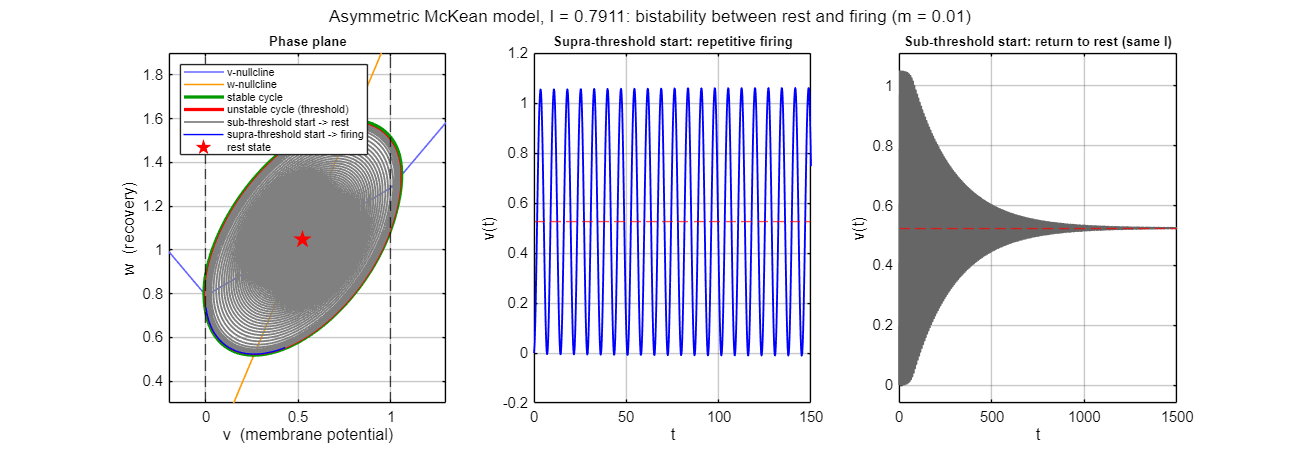

In [9]:
%% 4c-ii.  Back to the physical McKean model: rest versus repetitive firing
% Uses epsm, gam, sL, sR, m_demo, scen, aCf, cyc and the handles of the previous cells.
sC  = sC_of_m(m_demo);                 % central slope giving exactly m = m_demo
aC2 = scen(3);                         % stimulus level inside the two-cycle region
I2  = I_of_aC(aC2, sC);                % applied current
fprintf('Physical parameters: eps = %g, gamma = %g, slopes of f = (%g, %.5f, %g), applied current I = %.5f\n', epsm, gam, sL, sC, sR, I2);
fprintf('  current at which the pair of cycles is born: numerical I* = %.5f ,  prediction from (6.19): I* = %.5f\n', ...
        I_of_aC(aCf,sC), I_of_aC(aC_formula(m_demo, coef_(coef,sC,1), coef_(coef,sC,2)), sC));

% ---- inverse of the changes of variables (Propositions 3.5 and 3.6) --------------------------------------
MC = [sC/epsm, -1/epsm;  1, -gam];   TC = trace(MC);   DC = det(MC);
P  = [2, 0;  2*gam, -2/epsm];   c = [-1; -gam];                    % Proposition 3.5 with thresholds 0 and 1
NC = [TC 1; -DC 0];   dC = P*[I2/epsm; 0] - NC*c;
to_phys = @(x,y) (P \ ([x(:)'; sqrt(DC)*y(:)' - (dC(1) + TC/DC*dC(2))] - c))';    % (x,y) -> (v,w), one row per point
t_phys  = @(t) t/sqrt(DC);                                         % normalised time -> physical time

% ---- physical vector field ---------------------------------------------------------------------------
fv    = @(v) (v<=0).*sL.*v + (v>0 & v<=1).*sC.*v + (v>1).*(sC + sR*(v-1));
fphys = @(t,X) [(fv(X(1)) - X(2) + I2)/epsm;  X(1) - gam*X(2)];
vstar = (1 + aC2)/2;  wstar = vstar/gam;                          % equilibrium (central zone)
fprintf('Equilibrium (rest state): v* = %.4f, w* = %.4f  (stable focus: tr = %.4f < 0)\n', vstar, wstar, TC);

% ---- two initial conditions on the line v = 0: below and above the threshold (unstable cycle) (points of the line x = -1, i.e. v = 0) ----
kickA = to_phys(-1, 0.5*cyc.yu);                      % sub-threshold: inside the unstable cycle -> rest
kickB = to_phys(-1, 0.5*(cyc.yu + cyc.ys));           % between the two cycles     -> repetitive firing
opts  = odeset('RelTol',1e-10,'AbsTol',1e-12);
[tA,XA] = ode45(fphys, [0 1500], kickA', opts);      % the rest state is only weakly stable (m small): long run
[tB,XB] = ode45(fphys, [0 150], kickB', opts);
Cs = to_phys(cyc.s(:,1), cyc.s(:,2));   Cu = to_phys(cyc.u(:,1), cyc.u(:,2));      % the two cycles in the (v,w) plane
fprintf('Stable cycle: period %.3f (physical time units), v from %.3f to %.3f ;  unstable cycle: period %.3f\n', ...
        t_phys(cyc.Ts), min(Cs(:,1)), max(Cs(:,1)), t_phys(cyc.Tu));
fprintf('Check: orbit B at t = 150 lies on the stable cycle?  max v = %.3f (cycle: %.3f)\n', max(XB(tB>100,1)), max(Cs(:,1)));
fprintf('       orbit A at t = 1500: (v,w) = (%.4f, %.4f)  vs rest state (%.4f, %.4f)\n', XA(end,1), XA(end,2), vstar, wstar);

%% Figure 8 -- phase plane (v,w) and voltage traces
figure('Position',[50 50 1300 450]);
subplot(1,3,1);  hold on;  grid on;
vv = linspace(-0.4, 1.6, 400);
plot(vv, fv(vv) + I2, 'Color', [.4 .4 1], 'LineWidth', 1.2);  plot(vv, vv/gam, 'Color', [1 .6 0], 'LineWidth', 1.2);
xline(0,'k--','HandleVisibility','off');  xline(1,'k--','HandleVisibility','off');
plot(Cs(:,1), Cs(:,2), 'Color', [0 .6 0], 'LineWidth', 2.4);  plot(Cu(:,1), Cu(:,2), 'r', 'LineWidth', 2.4);
plot(XA(:,1), XA(:,2), 'Color', [.5 .5 .5]);  plot(XB(1:200,1), XB(1:200,2), 'b', 'LineWidth', 0.6);
plot(vstar, wstar, 'rp', 'MarkerFaceColor', 'r', 'MarkerSize', 10);
xlabel('v  (membrane potential)');  ylabel('w  (recovery)');  xlim([-0.2 1.3]);  ylim([0.3 1.9]);
title('Phase plane', 'FontSize', 10);
legend('v-nullcline','w-nullcline','stable cycle','unstable cycle (threshold)','sub-threshold start -> rest','supra-threshold start -> firing','rest state','Location','northwest','FontSize',8);

subplot(1,3,2);  plot(tB, XB(:,1), 'b');  hold on;  grid on;  yline(vstar, 'r--');
xlabel('t');  ylabel('v(t)');  title('Supra-threshold start: repetitive firing', 'FontSize', 10);  xlim([0 150]);
subplot(1,3,3);  plot(tA, XA(:,1), 'Color', [.4 .4 .4]);  hold on;  grid on;  yline(vstar, 'r--');
xlabel('t');  ylabel('v(t)');  title('Sub-threshold start: return to rest (same I)', 'FontSize', 10);  xlim([0 1500]);
ylim([min(XB(:,1))-0.05, max(XB(:,1))+0.05]);
sgtitle(sprintf('Asymmetric McKean model, I = %.4f: bistability between rest and firing (m = %g)', I2, m_demo), 'Color', 'k');

%% ---------------- local function ----------------
function v = coef_(coef, sC, idx)        % picks one output of coef(sC) = [tL,tR,dL,dR]
    [a1,a2,a3,a4] = coef(sC);  c = [a1 a2 a3 a4];  v = c(idx);
end


### 4d. Discussion of the results (System 2)

* **Hypotheses.** The standard McKean model has identical outer zones and so $t_L=t_R$; the first panel of Figure 5 shows what happens: for $m<0$ the return map has a single zero (one stable cycle, a Hopf-like transition) and for $m>0$ it has no zero (orbits spiral to the rest state). There is **no coexistence of two cycles** and no saddle-node near $\Gamma_0$, in agreement with the fact that Theorem 6.2 requires $t_Lt_R<0$. For the asymmetric model ($t_L=-\sqrt3,\ t_R=1/\sqrt3,\ \sigma=-8/3$) the second panel shows exactly the three situations of the theorem: for $a_C=0.0430$ the graph of $P(y)-y$ stays below zero (no cycle), for $a_C=0.0478$ it is tangent to zero (one semi-stable orbit), and for larger $a_C$ it crosses zero twice (two cycles).
* **Direction of the bifurcation.** Because $\sigma<0$, Theorem 6.2 puts the two-cycle region at $a_C>a_C^*(m)$ and the empty region below, which is what the shaded parameter plane (Figure 5, right) and the numerical points show. In terms of the stimulus: below $I^*$ the neuron can only rest; above $I^*$ a pair of cycles is created.
* **Accuracy of (6.19) and (6.20).** The numerically computed saddle-node points converge to the curve $a_C^*(m)$ of (6.19) as $m\to0$: the relative error is $0.3\,\%$ for $m=10^{-4}$, $1.3\,\%$ for $10^{-3}$ and $5.2\,\%$ for $10^{-2}$ (the formula is a leading-order term, $\mathcal O(m^{1/3})$ relative error). The ordinate (6.20) is $0.150$ for $m=0.01$ against $0.125$ numerically, with the same trend; the period (6.21) agrees with the simulated period to $4\cdot10^{-4}$ (e.g. $6.3032$ vs. $6.3016$ at $m=0.01$, and to 6 digits at $m=10^{-4}$). The parametrisation (6.18), truncated as printed in Lemma 6.1, is close to the curve but not more accurate than (6.19) in this example. All formulas are thus useful *starting values* (they land within a few percent of the true orbit) that a short Newton iteration turns into the exact orbit.
* **Saddle-node diagram (Figure 7).** At $m=0.01$ the stable cycle (green, multiplier $<1$) and the unstable cycle (red, multiplier $>1$) merge at the fold (blue square, multiplier $\to1$) and the branches have the typical square-root shape of a saddle-node; the multipliers of Figure 7 (right) verify the stability claims of Theorem 6.2, case 1. The unstable cycle shrinks towards the line $\{x=-1\}$ quickly as $a_C$ grows (red branch), so the coexistence window is narrow in $I$.
* **Phase portraits (Figure 6).** The upper row shows the orbits for the three cases; the lower row zooms at $\{x=-1\}$ where the crossing points $(−1,y_u)$ and $(−1,y_s)$ of the two cycles ($y_u=0.0479$, $y_s=0.178$) are visible. In the middle case a single semi-stable cycle exists; below it the orbits spiral in to the stable focus.
* **Neuronal interpretation (Figure 8).** With $I=0.7911$ (just above the threshold current $I^*=0.7904$ found numerically; formula (6.19) gives $0.7885$) the model has the stable rest state $(v^*,w^*)=(0.524,1.049)$ *and* a stable firing cycle of period $\approx7.26$ with $v\in[-0.01,1.06]$. The unstable cycle is the **threshold**: an initial condition inside the red cycle (sub-threshold) relaxes to rest, one between the two cycles (supra-threshold) triggers sustained firing, at the same current $I$. The rest state is only weakly stable ($\operatorname{tr}=-0.0087$) because $m$ is small, hence the slow decay of the right-hand voltage trace (note the different time scale).

---
## 5. Conclusion

The results of Chapters 5 and 6 of the thesis turn the qualitative theory of two bifurcations of continuous PWL systems into a *quantitative design tool* for two engineering models:

1. **Chua-type circuit (two zones).** After the canonical change of Proposition 3.3 the circuit is described by $(T_L,D_L,T_R,D_R,a)$. Theorem 5.1 predicts that when $T_L=-g_L-r$ becomes positive (the diode compensates the losses) a **stable limit cycle appears** through the FCLC bifurcation, gives the size $y_0^*\sim T_L^{1/3}$ of the crossing ordinate through (5.10), the other crossing $y_1$ and the period. The simulation confirms the stability (Floquet multiplier $<1$), the $T_L^{1/3}$ law, the period to six digits and the abrupt onset of a finite-amplitude oscillation (a sustained oscillation of $\approx2$ V at $\approx3.6$ kHz for the component values used), and it shows that (5.10) is an excellent initial condition for locating the cycle (error $<2\,\%$ for $T_L\le10^{-3}$).
2. **McKean neuron model (three zones).** After Propositions 3.5–3.6 the model depends on $(t_L,d_L,t_R,d_R;m,a_C)$ and the saddle-node of periodic orbits of Theorem 6.2 predicts a curve $a_C=a_C^*(m)\sim m^{2/3}$ in the (central-trace, stimulus) plane, with two cycles (firing + threshold) on one side, one semi-stable cycle on the curve and none on the other side. The formulas (6.19)–(6.21) are confirmed numerically as $m\to0$ (error $0.3\,\%$ at $m=10^{-4}$) and interpreted as a bistable, hysteretic transition between **rest and repetitive firing**. The theory also tells us when it does *not* apply: the standard McKean caricature has $t_L=t_R$ and only exhibits a Hopf-like transition, so an asymmetric version ($t_Lt_R<0$) is needed.

In both cases the thesis formulas provide (i) the location of the bifurcation in terms of physical parameters, (ii) initial conditions close enough to the periodic orbit for a single Newton or integration step to converge, and (iii) the stability information, so that the behaviour of the engineering system is predicted *before* simulating it.